# CAN-BERT training on your normal CAN capture (Colab, GPU)

Trains the masked-language-model (MLM) from *CAN-BERT do it?* (Alkhatib et al., arXiv:2210.09439) on the
normal-only windows in `canbert_normal_preparation_bundle.zip`, then measures how often it raises false alarms
on held-out normal traffic for different candidate-set sizes `k`.

**How to run**
1. `Runtime > Change runtime type > T4 GPU`.
2. `Runtime > Run all`. When the upload cell asks, pick `canbert_normal_preparation_bundle.zip`
   (or drag it into the Files pane first, or set `USE_DRIVE = True` below).
3. At the end the trained checkpoints and results are zipped and downloaded.

Training uses only normal data. The section at the end that injects frames is a **simulated sanity check of the
detection rule**, not a result you can report as attack detection. For that you need real captures (e.g. a labelled DoS run).

In [1]:
import json, math, os, random, shutil, time, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
import matplotlib.pyplot as plt

try:
    from google.colab import files, drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE = Path("/content") if IN_COLAB else Path.cwd()
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", dev,
      "|", torch.cuda.get_device_name(0) if dev.type == "cuda" else "no GPU")
if dev.type != "cuda":
    print("WARNING: no GPU found. In Colab use Runtime > Change runtime type > T4 GPU, then run again.")

torch 2.11.0+cu130 | device: cuda | Tesla T4


In [2]:
# ---- training (defaults follow the paper's Table II) ----
SEQ_LENGTHS   = [32]       # paper default T=32. Use [16, 32, 64, 128, 256] to repeat the paper's sweep.
MAX_EPOCHS    = 200
PATIENCE      = 10         # early stopping on validation MLM loss
BATCH_SIZE    = 32
LR            = 1e-3       # Adam, betas (0.9, 0.999)
WARMUP_STEPS  = 200        # linear LR warm-up (not in the paper; see the note below)
GRAD_CLIP     = 1.0        # max gradient norm (not in the paper); None disables
LR_FACTOR     = 0.5        # halve the LR when validation has not improved for LR_PATIENCE epochs (not in the paper)
LR_PATIENCE   = 3
MIN_LR        = 1e-5
MASK_RATIO    = 0.45
D_MODEL, N_LAYERS, N_HEADS, D_FF, DROPOUT = 256, 4, 1, 512, 0.1
WINDOW_STRIDE = 1          # use every n-th train/validation window. 1 = all (paper setting); 8 = quick run
SEED          = 42

# ---- evaluation ----
KS            = [1, 2, 3, 5]   # candidate-set sizes to evaluate (paper uses 5)
TARGET_FA     = 0.001          # smallest k whose false-alarm rate on VALIDATION normal windows is <= this
EVAL_PASSES   = 1              # random masks per window at inference (paper: 1)
SPOOF_ID      = 0x101          # known ID injected in the simulated spoofing test

# ---- files ----
ZIP_NAME  = "canbert_normal_preparation_bundle.zip"
USE_DRIVE = False              # True: mount Drive, read the zip from DRIVE_ZIP, copy results to DRIVE_OUT
DRIVE_ZIP = "/content/drive/MyDrive/canbert_normal_preparation_bundle.zip"
DRIVE_OUT = "/content/drive/MyDrive/canbert_outputs"

In [3]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")

def find_zip():
    if USE_DRIVE and Path(DRIVE_ZIP).exists():
        return Path(DRIVE_ZIP)
    if (BASE / ZIP_NAME).exists():
        return BASE / ZIP_NAME
    if IN_COLAB:
        print("Select", ZIP_NAME)
        up = files.upload()
        return Path(next(iter(up)))
    raise FileNotFoundError(f"Put {ZIP_NAME} next to this notebook.")

zip_path = find_zip()
EXTRACT = BASE / "canbert_bundle"
shutil.rmtree(EXTRACT, ignore_errors=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(EXTRACT)
DATA = next(EXTRACT.rglob("vocabulary.json")).parent
OUT = BASE / "canbert_outputs"
OUT.mkdir(exist_ok=True)

vocab = json.loads((DATA / "vocabulary.json").read_text())["token_to_id"]
SPECIAL = {"[PAD]", "[MASK]", "[UNK]"}
PAD_ID, MASK_ID, UNK_ID = vocab["[PAD]"], vocab["[MASK]"], vocab["[UNK]"]
observed = sorted(v for k, v in vocab.items() if k not in SPECIAL)   # token ids the model can predict
VOCAB_SIZE, N_OUT = len(vocab), len(observed)
cls_map = torch.full((VOCAB_SIZE,), -100, dtype=torch.long)          # token id -> output class (-100 = not predictable)
cls_map[torch.tensor(observed)] = torch.arange(N_OUT)
cls_map = cls_map.to(dev)
tok_to_canid = {v: int(k, 16) for k, v in vocab.items() if k not in SPECIAL}
canid_to_tok = {c: t for t, c in tok_to_canid.items()}

print("CAN IDs in vocabulary:", [hex(c) for c in sorted(canid_to_tok)])
print(pd.read_csv(DATA / "window_summary.csv").to_string(index=False))

Select canbert_normal_preparation_bundle.zip


Saving canbert_normal_preparation_bundle.zip to canbert_normal_preparation_bundle.zip
CAN IDs in vocabulary: ['0x101', '0x102', '0x103', '0x104', '0x105', '0x106', '0x107']
      split  sequence_length  frames_in_split  windows_stride_1  first_frame_index  last_frame_index_exclusive
      train               16            61493             61478                  0                       61493
 validation               16            13177             13162              61493                       74670
test_normal               16            13178             13163              74670                       87848
      train               32            61493             61462                  0                       61493
 validation               32            13177             13146              61493                       74670
test_normal               32            13178             13147              74670                       87848
      train               64            61493     

## Model, masking, training loop

This follows `train_canbert.py` (4 post-LN encoder layers, d=256, FFN 512, 1 head, dropout 0.1, mask ratio 0.45, Adam 1e-3,
batch 32, 200 epochs, patience 10) with these changes:

1. **Embedding init `std = d_model^-0.5`.** `train_canbert.py` multiplies a default-initialised embedding (std 1) by `sqrt(256)`,
   giving std 16, which drowns out the amplitude-1 positional encoding. The model then cannot tell the left neighbour from the
   right one and stays near the unigram baseline. On your data (CPU test, T=32), the original code was at loss 1.63 to 1.67
   after 600 steps (unigram baseline about 1.72); with this init it reached about 0.16 after 700 steps.
2. **200-step linear LR warm-up.** Not in the paper; it only stabilises the start of training.
3. **Gradient clipping (norm 1.0) and halving the LR when validation stalls for 3 epochs.** Not in the paper. In one Colab run on
   this data (T=32, constant LR 1e-3, no clipping) training was fine until epoch 17, then the loss jumped back to the 1.72
   no-context baseline and collapsed. The best checkpoint is only saved when validation improves, so it was unaffected, but the
   curves were ugly. The learning rate still starts at the paper's 1e-3.
4. **Vectorised masking** (same rule: round(0.45 * T) positions per window, uniformly at random) and **fixed validation masks**,
   so the validation loss used for early stopping is not noisy. Much faster on a GPU.

In [4]:
class CANBERT(nn.Module):
    def __init__(self, max_len):
        super().__init__()
        self.d = D_MODEL
        self.emb = nn.Embedding(VOCAB_SIZE, D_MODEL, padding_idx=PAD_ID)
        nn.init.normal_(self.emb.weight, mean=0.0, std=D_MODEL ** -0.5)
        with torch.no_grad():
            self.emb.weight[PAD_ID].zero_()
        pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, D_MODEL, 2, dtype=torch.float32) * (-math.log(10000.0) / D_MODEL))
        pe = torch.zeros(max_len, D_MODEL)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))
        layer = nn.TransformerEncoderLayer(D_MODEL, N_HEADS, D_FF, DROPOUT, activation="relu",
                                           batch_first=True, norm_first=False)
        self.encoder = nn.TransformerEncoder(layer, N_LAYERS, enable_nested_tensor=False)
        self.head = nn.Linear(D_MODEL, N_OUT)

    def forward(self, x):                     # windows contain no [PAD], so no padding mask is needed
        z = self.emb(x) * math.sqrt(self.d) + self.pe[:, : x.size(1)]
        return self.head(self.encoder(z))


def make_mask(x, ratio, gen=None):
    # True at round(ratio * T) random positions per window
    n = max(1, int(round(x.size(1) * ratio)))
    r = torch.rand(x.shape, device=x.device, generator=gen)
    return r.argsort(dim=1).argsort(dim=1) < n


def to_dev(a):
    return torch.from_numpy(a.astype(np.int64)).to(dev)


@torch.no_grad()
def eval_mlm(model, X, chosen):
    model.eval()
    tot, hit, n = 0.0, 0, 0
    for i in range(0, len(X), 1024):
        xb, ch = X[i:i + 1024], chosen[i:i + 1024]
        lg = model(xb.masked_fill(ch, MASK_ID))[ch]
        lab = cls_map[xb][ch]
        tot += F.cross_entropy(lg, lab, reduction="sum").item()
        hit += (lg.argmax(-1) == lab).sum().item()
        n += lab.numel()
    return tot / n, hit / n


def train_one(T):
    set_seed(SEED)
    Xtr = to_dev(np.load(DATA / f"train_T{T}.npy")[::WINDOW_STRIDE])
    Xva = to_dev(np.load(DATA / f"validation_T{T}.npy")[::WINDOW_STRIDE])
    assert len(Xtr) > 0 and len(Xva) > 0, "empty windows"
    assert int(Xtr.min()) >= len(SPECIAL), "unexpected special tokens in training windows"
    gen = torch.Generator(device=dev).manual_seed(SEED + 1)
    val_chosen = make_mask(Xva, MASK_RATIO, gen)          # fixed masks -> comparable validation loss every epoch

    model = CANBERT(T).to(dev)
    print(f"T={T}: {len(Xtr):,} train / {len(Xva):,} val windows, {sum(p.numel() for p in model.parameters()):,} parameters")
    opt = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999))
    ckpt_path = OUT / f"canbert_T{T}.pt"

    best, bad, lr_bad, lr_scale, step, hist = float("inf"), 0, 0, 1.0, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        model.train()
        perm = torch.randperm(len(Xtr), device=dev)
        tot, nb = torch.zeros((), device=dev), 0
        for i in range(0, len(Xtr), BATCH_SIZE):
            xb = Xtr[perm[i:i + BATCH_SIZE]]
            ch = make_mask(xb, MASK_RATIO)
            logits = model(xb.masked_fill(ch, MASK_ID))
            labels = torch.where(ch, cls_map[xb], torch.full_like(xb, -100))
            loss = F.cross_entropy(logits.reshape(-1, N_OUT), labels.reshape(-1), ignore_index=-100)
            cur_lr = LR * lr_scale * min(1.0, (step + 1) / max(1, WARMUP_STEPS))   # warm-up x plateau decay
            for g in opt.param_groups:
                g["lr"] = cur_lr
            opt.zero_grad(set_to_none=True)
            loss.backward()
            if GRAD_CLIP:
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            opt.step()
            step += 1
            tot += loss.detach()
            nb += 1
        tr_loss = (tot / nb).item()
        va_loss, va_acc = eval_mlm(model, Xva, val_chosen)
        improved = va_loss < best
        hist.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss, "val_top1": va_acc, "lr": cur_lr})
        print(f"epoch {epoch:3d} | train {tr_loss:.5f} | val {va_loss:.5f} | val top-1 {va_acc:.4f} | "
              f"lr {cur_lr:.1e} | {time.time() - t0:4.0f}s {'*' if improved else ''}")
        lr_bad = 0 if improved else lr_bad + 1
        if lr_bad >= LR_PATIENCE and LR * lr_scale * LR_FACTOR >= MIN_LR:
            lr_scale *= LR_FACTOR
            lr_bad = 0
            print(f"          validation stalled for {LR_PATIENCE} epochs -> LR x{LR_FACTOR} (now {LR * lr_scale:.1e})")
        if improved:
            best, bad = va_loss, 0
            torch.save({
                "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "vocabulary": vocab, "output_ids": observed, "sequence_length": T,
                "config": {"layers": N_LAYERS, "d_model": D_MODEL, "ffn": D_FF, "heads": N_HEADS,
                           "dropout": DROPOUT, "mask_ratio": MASK_RATIO, "lr": LR, "warmup_steps": WARMUP_STEPS,
                           "grad_clip": GRAD_CLIP, "lr_factor": LR_FACTOR, "lr_patience": LR_PATIENCE,
                           "batch_size": BATCH_SIZE, "window_stride": WINDOW_STRIDE, "seed": SEED,
                           "best_val_mlm_loss": float(best), "epoch": epoch},
            }, ckpt_path)
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"early stopping: no improvement for {PATIENCE} epochs")
                break
    (OUT / f"history_T{T}.json").write_text(json.dumps(hist, indent=2))
    print(f"T={T}: best validation MLM loss {best:.5f} -> {ckpt_path.name}\n")
    return hist

## Train

In [5]:
HISTORY = {}
for T in SEQ_LENGTHS:
    HISTORY[T] = train_one(T)

T=32: 61,462 train / 13,146 val windows, 2,112,775 parameters
epoch   1 | train 0.26206 | val 0.05738 | val top-1 0.9770 | lr 1.0e-03 |   25s *
epoch   2 | train 0.08688 | val 0.03816 | val top-1 0.9853 | lr 1.0e-03 |   22s *
epoch   3 | train 0.07292 | val 0.03687 | val top-1 0.9859 | lr 1.0e-03 |   22s *
epoch   4 | train 0.06382 | val 0.02519 | val top-1 0.9910 | lr 1.0e-03 |   22s *
epoch   5 | train 0.05747 | val 0.02140 | val top-1 0.9922 | lr 1.0e-03 |   22s *
epoch   6 | train 0.05407 | val 0.02211 | val top-1 0.9924 | lr 1.0e-03 |   22s 
epoch   7 | train 0.04877 | val 0.01595 | val top-1 0.9945 | lr 1.0e-03 |   22s *
epoch   8 | train 0.04563 | val 0.01471 | val top-1 0.9946 | lr 1.0e-03 |   22s *
epoch   9 | train 0.04413 | val 0.01223 | val top-1 0.9956 | lr 1.0e-03 |   22s *
epoch  10 | train 0.04166 | val 0.01291 | val top-1 0.9955 | lr 1.0e-03 |   22s 
epoch  11 | train 0.03999 | val 0.01212 | val top-1 0.9956 | lr 1.0e-03 |   22s *
epoch  12 | train 0.03719 | val 0.0098

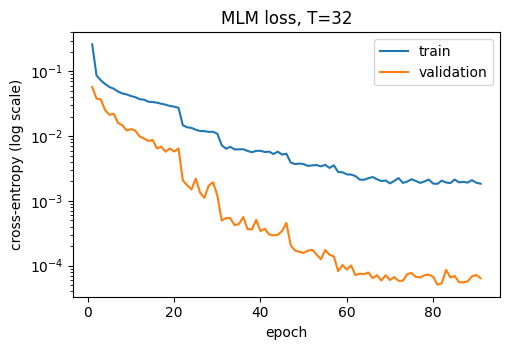

In [6]:
fig, axes = plt.subplots(1, len(SEQ_LENGTHS), figsize=(5.2 * len(SEQ_LENGTHS), 3.6), squeeze=False)
for ax, T in zip(axes[0], SEQ_LENGTHS):
    h = HISTORY[T]
    ax.plot([e["epoch"] for e in h], [e["train_loss"] for e in h], label="train")
    ax.plot([e["epoch"] for e in h], [e["val_loss"] for e in h], label="validation")
    ax.set_yscale("log")
    ax.set_title(f"MLM loss, T={T}"); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy (log scale)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "loss_curves.png", dpi=150); plt.show()

## False alarms on held-out normal traffic

Decision rule from the paper: mask 45% of a window's IDs at random; for each masked position take the model's `k` most likely IDs;
if the true ID is not among them, the window is flagged abnormal. A window containing an ID that is not in the vocabulary
(mapped to `[UNK]`) is always flagged when that position is masked, because `[UNK]` is never a candidate.

The paper uses `k = 5`. This bus has only 7 IDs, so `k = 5` accepts almost any known ID and would miss attacks that
reuse known IDs. The cell below therefore reports several `k` and picks the smallest one whose false-alarm rate on the
**validation normal** windows is at most `TARGET_FA`. That choice uses normal data only; state it as an adaptation in the thesis.

In [7]:
def load_model(T):
    ck = torch.load(OUT / f"canbert_T{T}.pt", map_location=dev)
    m = CANBERT(T).to(dev)
    m.load_state_dict(ck["state_dict"])
    return m.eval()


@torch.no_grad()
def flag_windows(model, X, ks, seed):
    # {k: bool array}, True = window flagged abnormal
    model.eval()
    gen = torch.Generator(device=dev).manual_seed(seed)
    flags = {k: torch.zeros(len(X), dtype=torch.bool, device=dev) for k in ks}
    for _ in range(EVAL_PASSES):
        for i in range(0, len(X), 1024):
            xb = X[i:i + 1024]
            ch = make_mask(xb, MASK_RATIO, gen)
            top = model(xb.masked_fill(ch, MASK_ID)).topk(max(ks), dim=-1).indices   # (B, T, K) output classes
            true_cls = cls_map[xb].unsqueeze(-1)                                      # -100 for [UNK]: never a hit
            for k in ks:
                hit = (top[..., :k] == true_cls).any(-1)
                flags[k][i:i + len(xb)] |= (ch & ~hit).any(1)
    return {k: v.cpu().numpy() for k, v in flags.items()}


MODELS, RESULTS = {}, {}
for T in SEQ_LENGTHS:
    MODELS[T] = load_model(T)
    Xva = to_dev(np.load(DATA / f"validation_T{T}.npy"))
    Xte = to_dev(np.load(DATA / f"test_normal_T{T}.npy"))
    fa_val = {k: float(v.mean()) for k, v in flag_windows(MODELS[T], Xva, KS, SEED + 100).items()}
    fa_test = {k: float(v.mean()) for k, v in flag_windows(MODELS[T], Xte, KS, SEED + 200).items()}
    ok = [k for k in KS if fa_val[k] <= TARGET_FA]
    k_star = min(ok) if ok else max(KS)
    if not ok:
        print(f"T={T}: no k reached the {TARGET_FA:.2%} target on validation; falling back to k={k_star}. "
              "Train longer, or raise TARGET_FA and say so in the thesis.")
    RESULTS[T] = {"chosen_k": k_star, "false_alarm_validation": fa_val, "false_alarm_test_normal": fa_test,
                  "n_validation_windows": len(Xva), "n_test_windows": len(Xte)}
    print(f"T={T}  (chosen k = {k_star}, target false-alarm <= {TARGET_FA:.2%} on validation)")
    print(pd.DataFrame({"k": KS, "validation FA": [f"{fa_val[k]:.3%}" for k in KS],
                        "test-normal FA": [f"{fa_test[k]:.3%}" for k in KS]}).to_string(index=False), "\n")

T=32  (chosen k = 1, target false-alarm <= 0.10% on validation)
 k validation FA test-normal FA
 1        0.015%         0.015%
 2        0.000%         0.000%
 3        0.000%         0.000%
 5        0.000%         0.000% 



## Simulated injection check (optional, not a result)

Injects frames into the held-out **normal test stream** (rebuilt from the saved windows) in blocks covering about 25% of it,
then scores windows with the rule above. This only shows that the mechanism responds to broken ID patterns.
It is **not** a measurement of real DoS or spoofing detection: the injected IDs and rates are made up.
Replace it with your real attack captures when you have them.

- `flooding`: ID `0x000` (not in the vocabulary, so `[UNK]`), about one extra frame per two normal frames
- `fuzzy`: random 11-bit IDs at the same rate
- `spoof`: a known ID (`SPOOF_ID`) inserted at about 15% of positions

In [8]:
def stream_from_windows(W):
    return np.concatenate([W[0], W[1:, -1]]).astype(np.int64)


def inject(stream, kind, rng, rate, block_len=1500, coverage=0.25):
    n = len(stream)
    in_block = np.zeros(n, bool)
    for s in rng.choice(n - block_len, max(1, int(coverage * n / block_len)), replace=False):
        in_block[s:s + block_len] = True
    extra = in_block & (rng.random(n) < rate)
    counts = 1 + extra.astype(np.int64)
    out = np.repeat(stream, counts)
    pos = (np.cumsum(counts) - counts)[extra] + 1              # slot of each inserted frame
    if kind == "flooding":
        new = np.full(len(pos), UNK_ID)
    elif kind == "fuzzy":
        new = np.array([canid_to_tok.get(int(r), UNK_ID) for r in rng.integers(0, 0x800, len(pos))], dtype=np.int64)
    else:
        new = np.full(len(pos), canid_to_tok[SPOOF_ID])
    out[pos] = new
    inj = np.zeros(len(out), bool)
    inj[pos] = True
    return out, inj


def prf(y, p):
    tp, fp, fn = int((y & p).sum()), int((~y & p).sum()), int((y & ~p).sum())
    pr = tp / (tp + fp) if tp + fp else 0.0
    rc = tp / (tp + fn) if tp + fn else 0.0
    return pr, rc, (2 * pr * rc / (pr + rc) if pr + rc else 0.0)


ATTACKS = {"flooding": 0.5, "fuzzy": 0.5, "spoof": 0.15}
for T in SEQ_LENGTHS:
    base = stream_from_windows(np.load(DATA / f"test_normal_T{T}.npy"))
    RESULTS[T]["simulated_injection"] = {}
    rows = []
    for a, (kind, rate) in enumerate(ATTACKS.items()):
        rng = np.random.default_rng(SEED + 10 + a)
        toks, inj = inject(base, kind, rng, rate)
        y = np.lib.stride_tricks.sliding_window_view(inj, T).any(axis=1)
        X = to_dev(np.ascontiguousarray(np.lib.stride_tricks.sliding_window_view(toks, T)))
        flags = flag_windows(MODELS[T], X, KS, SEED + 300 + a)
        RESULTS[T]["simulated_injection"][kind] = {}
        for k in KS:
            pr, rc, f1 = prf(y, flags[k])
            RESULTS[T]["simulated_injection"][kind][k] = {"precision": pr, "recall": rc, "f1": f1}
            rows.append({"attack": kind, "k": f"{k}{'*' if k == RESULTS[T]['chosen_k'] else ''}",
                         "precision": f"{pr:.3f}", "recall": f"{rc:.3f}", "F1": f"{f1:.3f}",
                         "attacked windows": f"{int(y.sum())}/{len(y)}"})
    print(f"T={T}   (* = k chosen on normal validation data; SIMULATED injections)")
    print(pd.DataFrame(rows).to_string(index=False), "\n")

T=32   (* = k chosen on normal validation data; SIMULATED injections)
  attack  k precision recall    F1 attacked windows
flooding 1*     1.000  0.999 0.999       4579/14671
flooding  2     1.000  0.999 0.999       4579/14671
flooding  3     1.000  0.999 0.999       4579/14671
flooding  5     1.000  0.998 0.999       4579/14671
   fuzzy 1*     1.000  0.999 0.999       4585/14672
   fuzzy  2     1.000  0.998 0.999       4585/14672
   fuzzy  3     1.000  0.998 0.999       4585/14672
   fuzzy  5     1.000  0.997 0.998       4585/14672
   spoof 1*     0.999  0.995 0.997       2937/13548
   spoof  2     1.000  0.980 0.990       2937/13548
   spoof  3     1.000  0.944 0.971       2937/13548
   spoof  5     1.000  0.648 0.787       2937/13548 



## Save and download

In [9]:
(OUT / "results.json").write_text(json.dumps(
    {"settings": {"SEQ_LENGTHS": SEQ_LENGTHS, "KS": KS, "TARGET_FA": TARGET_FA, "EVAL_PASSES": EVAL_PASSES,
                  "MASK_RATIO": MASK_RATIO, "WINDOW_STRIDE": WINDOW_STRIDE, "SEED": SEED},
     "results": {str(T): RESULTS[T] for T in RESULTS}}, indent=2))

archive = shutil.make_archive(str(BASE / "canbert_outputs"), "zip", OUT)
print("saved:", sorted(p.name for p in OUT.iterdir()))
if USE_DRIVE and IN_COLAB:
    shutil.copytree(OUT, DRIVE_OUT, dirs_exist_ok=True)
    print("copied to", DRIVE_OUT)
if IN_COLAB:
    files.download(archive)
else:
    print("archive:", archive)

saved: ['canbert_T32.pt', 'history_T32.json', 'loss_curves.png', 'results.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>